# 2. Model, results and interpretability

**Approach:** a **ResNet18** convolutional neural network, pre-trained on millions of general images (*transfer learning*), is fine-tuned in its last layers to recognise retinal diseases in OCT. This is a standard technique when little medical data is available.

**Metrics used:**
- **Macro F1:** average per-disease performance (combines sensitivity and precision). It is used instead of plain accuracy because the dataset is imbalanced.
- **AUC:** ability of the model to separate one disease from the rest (1 = perfect, 0.5 = chance).
- **Grad-CAM:** a heatmap showing which regions of the image the model relied on to make its decision.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, f1_score, roc_auc_score)
from torch.utils.data import DataLoader

from common import OCTDataset, build_model, get_device, grad_cam, make_transforms, set_seed
from train import run_epoch

ROOT = Path.cwd().parent
MANIFEST = ROOT / "data" / "manifest.csv"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

EPOCHS, BATCH_SIZE, LR, IMG_SIZE, SEED = 10, 32, 1e-3, 224, 42

set_seed(SEED)
device = get_device()
print("Compute device:", device)

Compute device: cpu


## Data preparation

In [2]:
df = pd.read_csv(MANIFEST)
classes = sorted(df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
train_df, val_df, test_df = [df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")]

train_tfm, eval_tfm = make_transforms(IMG_SIZE)
train_dl = DataLoader(OCTDataset(train_df, class_to_idx, train_tfm), batch_size=BATCH_SIZE, shuffle=True)
val_dl = DataLoader(OCTDataset(val_df, class_to_idx, eval_tfm), batch_size=BATCH_SIZE)
test_dl = DataLoader(OCTDataset(test_df, class_to_idx, eval_tfm), batch_size=BATCH_SIZE)

# More weight for diseases with few images (compensates for class imbalance)
counts = train_df["label"].value_counts().reindex(classes).fillna(1).values
class_weights = torch.tensor(len(train_df) / (len(classes) * counts), dtype=torch.float32).to(device)
pd.Series(class_weights.cpu().numpy(), index=classes, name="loss weight").round(2)

AMD     0.240000
DME     1.990000
ERM     1.900000
NO      0.890000
RAO    16.059999
RVO     2.900000
VID     3.930000
Name: loss weight, dtype: float32

## Training

In [3]:
model = build_model(len(classes), pretrained=True, freeze=True).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR)

history, best_f1 = [], -1.0
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_f1 = run_epoch(model, train_dl, device, criterion, optimizer)
    va_loss, va_f1 = run_epoch(model, val_dl, device, criterion)
    history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_f1=tr_f1, val_f1=va_f1))
    print(f"Epoch {epoch:02d} | train: loss {tr_loss:.3f}, F1 {tr_f1:.3f} | "
          f"validation: loss {va_loss:.3f}, F1 {va_f1:.3f}")
    if va_f1 > best_f1:  # keep the best model according to validation F1
        best_f1 = va_f1
        torch.save({"model_state": model.state_dict(), "classes": classes, "img_size": IMG_SIZE},
                   OUT_DIR / "best.pt")

history = pd.DataFrame(history)
print(f"\nBest validation macro-F1: {best_f1:.3f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\angel/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Epoch 01 | train: loss 1.300, F1 0.427 | validation: loss 1.034, F1 0.627
Epoch 02 | train: loss 0.578, F1 0.715 | validation: loss 0.539, F1 0.726
Epoch 03 | train: loss 0.402, F1 0.794 | validation: loss 0.488, F1 0.770
Epoch 04 | train: loss 0.317, F1 0.851 | validation: loss 0.529, F1 0.791
Epoch 05 | train: loss 0.280, F1 0.843 | validation: loss 0.651, F1 0.723
Epoch 06 | train: loss 0.325, F1 0.849 | validation: loss 0.411, F1 0.773
Epoch 07 | train: loss 0.247, F1 0.870 | validation: loss 0.350, F1 0.820
Epoch 08 | train: loss 0.184, F1 0.892 | validation: loss 0.471, F1 0.756
Epoch 09 | train: loss 0.166, F1 0.926 | validation: loss 0.291, F1 0.850
Epoch 10 | train: loss 0.168, F1 0.927 | validation: loss 0.404, F1 0.838

Best validation macro-F1: 0.850


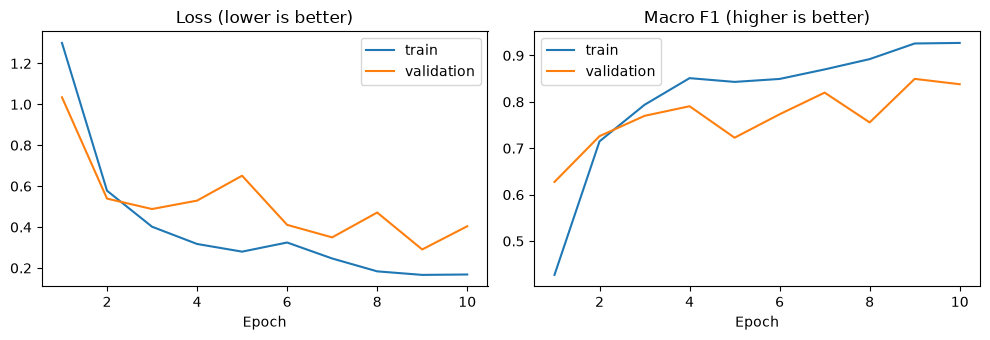

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history.epoch, history.train_loss, label="train")
axes[0].plot(history.epoch, history.val_loss, label="validation")
axes[0].set_title("Loss (lower is better)")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.epoch, history.train_f1, label="train")
axes[1].plot(history.epoch, history.val_f1, label="validation")
axes[1].set_title("Macro F1 (higher is better)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "training_curves.png", dpi=150)
plt.show()

## Final evaluation on the test set
These images belong to patients the model **never saw** during training or during selection of the best model.

In [5]:
ckpt = torch.load(OUT_DIR / "best.pt", map_location=device)
model = build_model(len(classes), pretrained=False, freeze=False)
model.load_state_dict(ckpt["model_state"])
model.to(device).eval()

probs, y_true = [], []
with torch.no_grad():
    for x, y in test_dl:
        probs.append(torch.softmax(model(x.to(device)), 1).cpu().numpy())
        y_true += y.tolist()
probs, y_true = np.concatenate(probs), np.array(y_true)
y_pred = probs.argmax(1)

labels = list(range(len(classes)))
print(classification_report(y_true, y_pred, labels=labels, target_names=classes, digits=3, zero_division=0))
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro', zero_division=0):.3f}")
try:
    auc = roc_auc_score(y_true, probs, multi_class="ovr", average="macro", labels=labels)
    print(f"Macro AUC: {auc:.3f}")
except ValueError:
    print("Macro AUC could not be computed (a disease is missing from the test set)")

              precision    recall  f1-score   support

         AMD      0.970     0.935     0.952       246
         DME      0.694     0.862     0.769        29
         ERM      0.694     0.806     0.746        31
          NO      0.775     0.833     0.803        66
         RAO      1.000     1.000     1.000         7
         RVO      0.900     0.450     0.600        20
         VID      0.882     1.000     0.938        15

    accuracy                          0.884       414
   macro avg      0.845     0.841     0.830       414
weighted avg      0.893     0.884     0.884       414

Macro F1: 0.830
Macro AUC: 0.986


In the confusion matrix, each row is the true disease and each column is what the model predicts. Correct predictions lie on the diagonal.

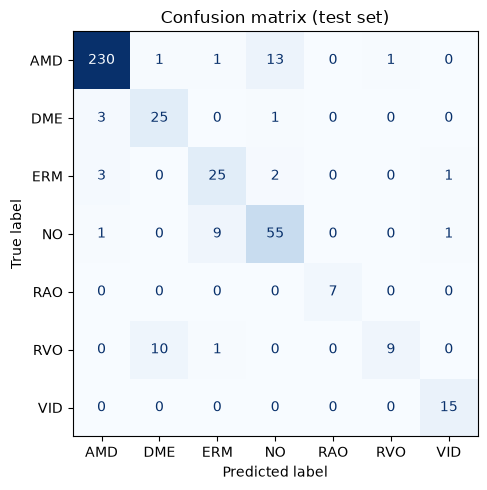

In [6]:
cm = confusion_matrix(y_true, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (test set)")
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## What does the model look at? (Grad-CAM)
**Red/yellow** regions are those that most influenced the model's decision. A trustworthy model should focus on retinal regions with clinical meaning rather than on image borders, text or artefacts.

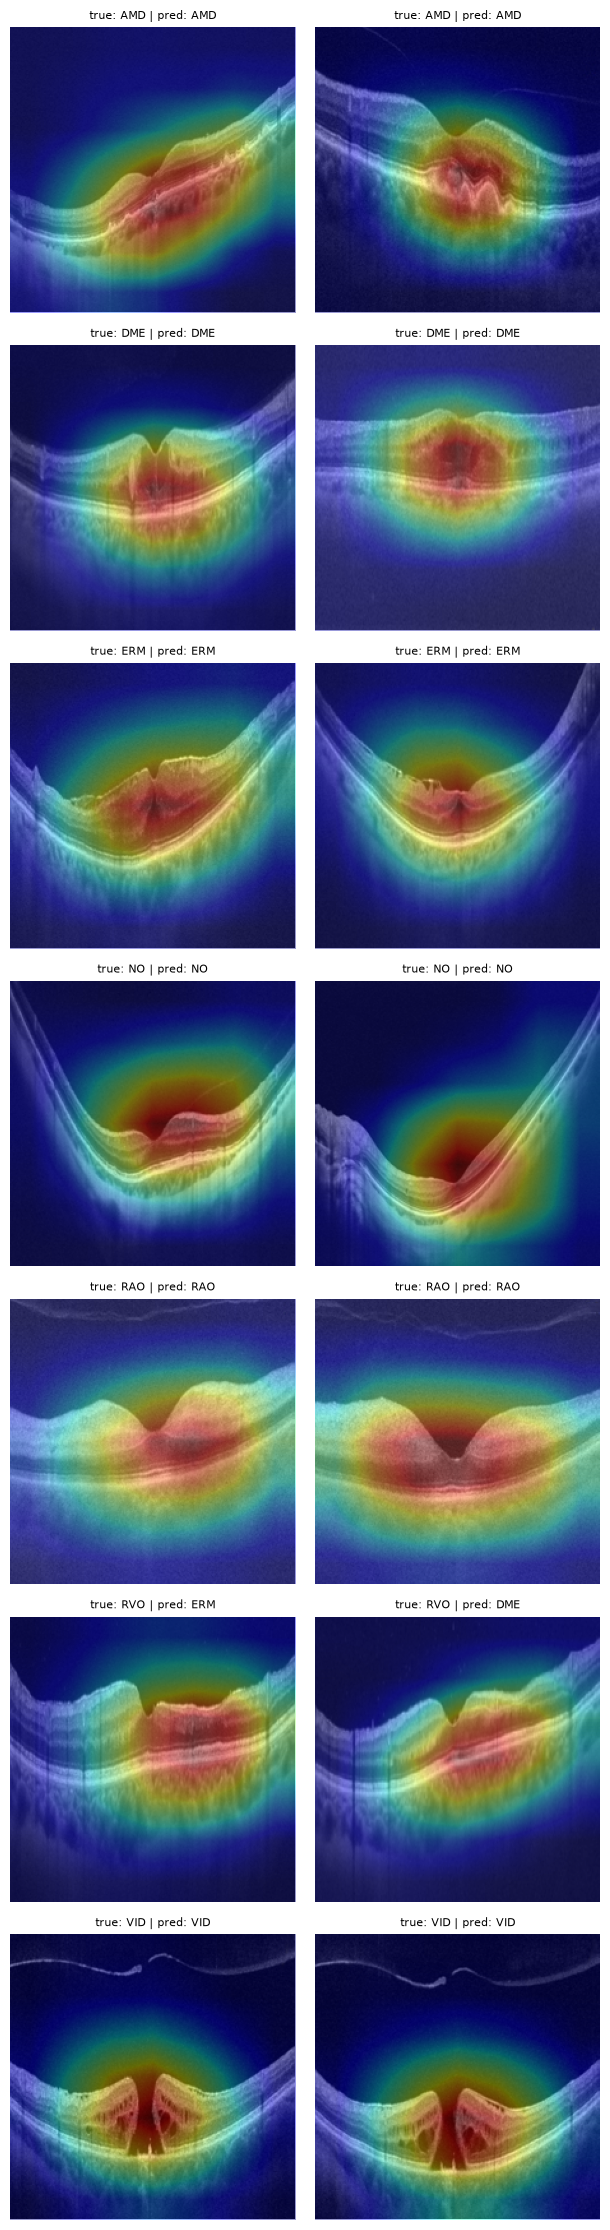

In [7]:
N_PER_CLASS = 2
fig, axes = plt.subplots(len(classes), N_PER_CLASS, figsize=(3.2 * N_PER_CLASS, 3.2 * len(classes)), squeeze=False)
for ci, cname in enumerate(classes):
    subset = test_df[test_df.label == cname].head(N_PER_CLASS)
    for j in range(N_PER_CLASS):
        ax = axes[ci][j]
        ax.axis("off")
        if j >= len(subset):
            continue
        pil = Image.open(subset.iloc[j]["path"]).convert("RGB")
        x = eval_tfm(pil).unsqueeze(0).to(device)
        cam, pred_idx = grad_cam(model, x, model.layer4)
        ax.imshow(pil.resize((IMG_SIZE, IMG_SIZE)))
        ax.imshow(cam, cmap="jet", alpha=0.4, extent=(0, IMG_SIZE, IMG_SIZE, 0), interpolation="bilinear")
        ax.set_title(f"true: {cname} | pred: {classes[pred_idx]}", fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "gradcam.png", dpi=150)
plt.show()

## Conclusions and limitations

**Overall performance (test set: 414 images from 162 patients never seen during training).** Macro F1 = 0.830, accuracy = 0.884 and macro AUC = 0.986. AMD (F1 0.95) and VID (F1 0.94) are classified best. RAO reaches F1 = 1.00, but it has only 7 test images (11 patients in the whole dataset), so that figure is not reliable.

**Main errors (confusion matrix).**
- **RVO is the weakest class (recall 0.45):** 10 of 20 RVO images were predicted as DME and 1 as ERM. A plausible explanation, to be confirmed by a clinician, is that retinal vein occlusion often causes macular edema, which can look similar to DME on OCT.
- **Normal retinas** were sometimes labelled ERM (9 of 66), and 13 AMD images (5%) were labelled normal. The latter lowers the precision of the normal class (0.78).

**Interpretability (Grad-CAM).** For all classes the model concentrates on the central retina (around the fovea and the retinal layers) and not on image borders or background, which is reassuring. However, the maps are coarse (low-resolution feature maps upsampled to the image size) and look similar across classes, partly because OCT scans are centred on the macula. They therefore do not prove that the model identifies specific lesions. The two RVO examples shown are misclassified (predicted ERM and DME), and the model attends to the same central region in them.

**Training behaviour.** Training F1 (0.93) is higher than validation F1 (about 0.84), indicating mild overfitting, and the validation curve is noisy because rare classes have very few validation images. The "best" epoch (epoch 9) was therefore selected on a noisy signal and the validation curve was still improving, so longer training or a learning-rate schedule might help.

**Limitations.**
- Rare classes have very few test cases (RAO 7, VID 15, RVO 20), so their metrics have wide uncertainty; no confidence intervals were computed.
- A single dataset and a single patient-level split were used; the model was not validated on data from another centre or OCT device.
- The interpretation of errors and heatmaps has not been reviewed by a clinician.


**Possible improvements:** patient-level cross-validation with bootstrap confidence intervals, external validation on another OCT dataset, longer training with a learning-rate schedule, comparison with other architectures, and segmentation to quantify imaging biomarkers (e.g. fluid volume).